# Predicting Smartphone Addiction
**Kaggle Playground Series S6E8** — Binary Classification  
**Metric**: AUC-ROC (predict probability of `addicted_label`)

## 0. Setup & Imports

In [11]:
import os
import zipfile
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OrdinalEncoder

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
N_FOLDS = 5
TARGET = 'addicted_label'

np.random.seed(SEED)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', palette='muted')
print('All imports OK')

All imports OK


## 1. Download Dataset (run once)

In [ ]:
# Skip if dataset already exists
if not os.path.exists('./dataset/train.csv'):
    import kaggle as kg
    kg.api.authenticate()
    competition_name = "playground-series-s6e8"
    download_path = "./dataset"
    kg.api.competition_download_files(competition_name, path=download_path)
    zip_file_path = os.path.join(download_path, f"{competition_name}.zip")
    if os.path.exists(zip_file_path):
        with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
            zip_ref.extractall(download_path)
        os.remove(zip_file_path)
    print('Download complete!')
else:
    print('Dataset already exists, skipping download.')

Dataset already exists, skipping download.


## 2. Load Data

In [13]:
train = pd.read_csv('./dataset/train.csv')
test  = pd.read_csv('./dataset/test.csv')
sub   = pd.read_csv('./dataset/sample_submission.csv')

print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')
train.head()

Train shape: (691369, 14)
Test shape:  (296302, 13)


,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


## 3. Exploratory Data Analysis (EDA)

In [14]:
# --- Dtypes & missing values ---
missing = train.isnull().sum().rename('missing_count')
missing_pct = (train.isnull().mean() * 100).rename('missing_%').round(2)
print(pd.concat([train.dtypes.rename('dtype'), missing, missing_pct], axis=1).to_string())

                           dtype  missing_count  missing_%
id                         int64              0       0.00
age                      float64          28929       4.18
daily_screen_time_hours  float64          95854      13.86
social_media_hours       float64         133995      19.38
gaming_hours             float64         126821      18.34
work_study_hours         float64          51518       7.45
sleep_hours              float64          44480       6.43
notifications_per_day    float64          67584       9.78
app_opens_per_day        float64          80710      11.67
weekend_screen_time      float64         112063      16.21
gender                       str          29034       4.20
stress_level                 str          55148       7.98
academic_work_impact         str          44224       6.40
addicted_label             int64              0       0.00


Class distribution (%):
addicted_label
1    70.94
0    29.06
Name: proportion, dtype: float64


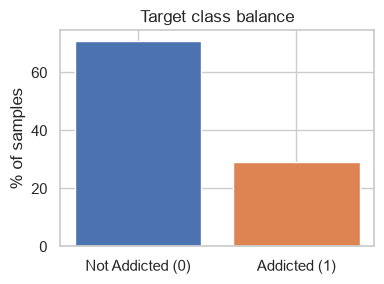

In [15]:
# --- Class balance ---
vc = train[TARGET].value_counts(normalize=True)
print('Class distribution (%):')
print((vc * 100).round(2))

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(['Not Addicted (0)', 'Addicted (1)'], vc.values * 100, color=['#4C72B0', '#DD8452'])
ax.set_ylabel('% of samples')
ax.set_title('Target class balance')
plt.tight_layout()
plt.show()

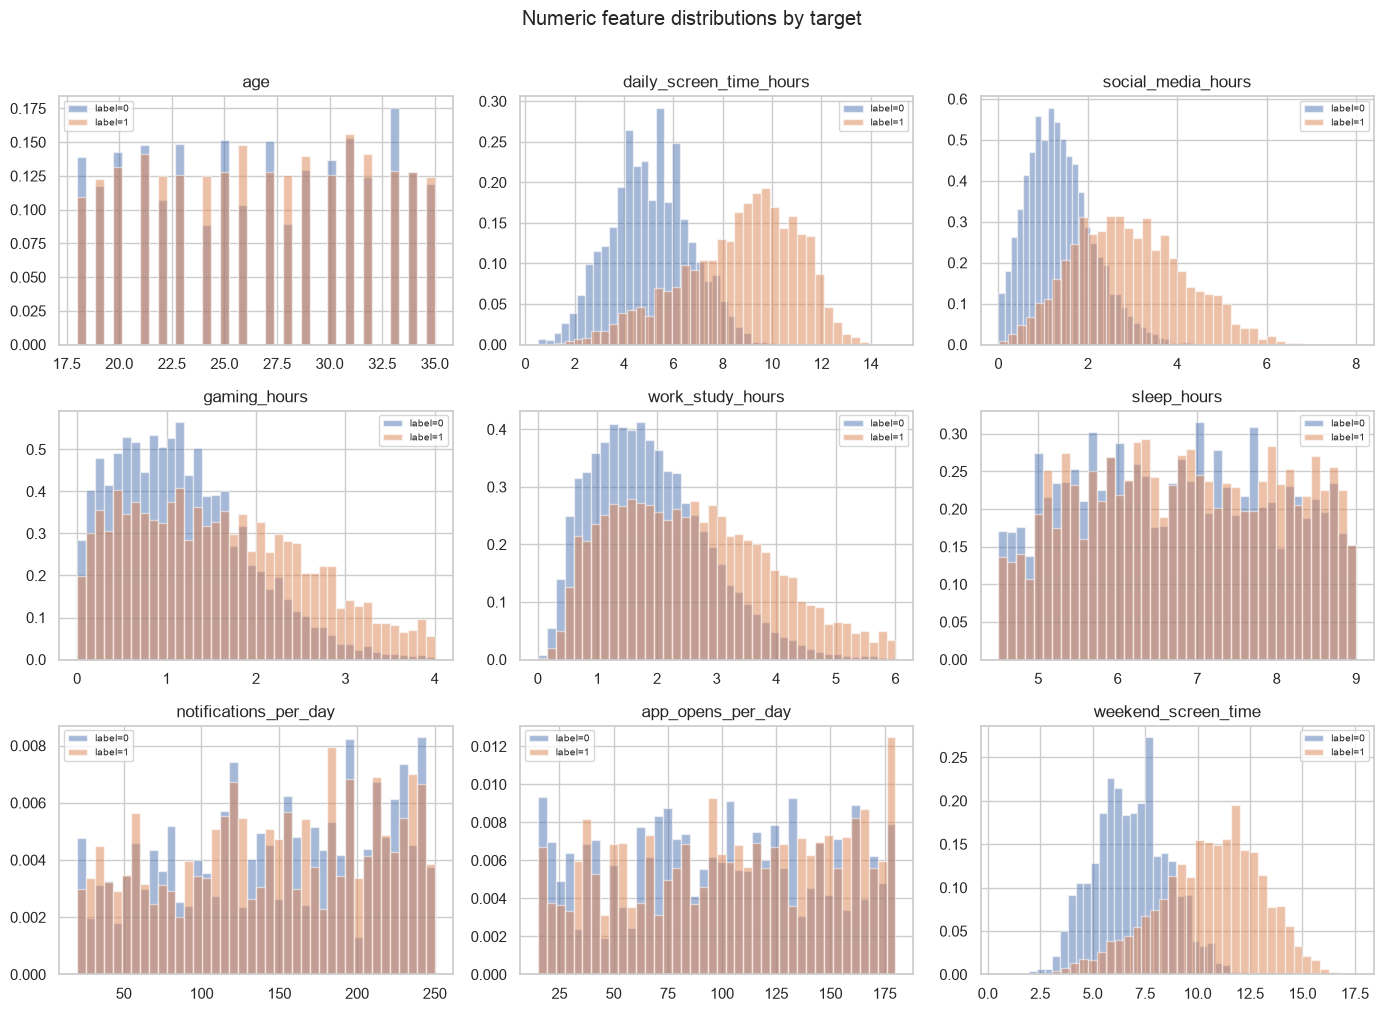

In [16]:
# --- Numeric feature distributions by target ---
num_cols = ['age', 'daily_screen_time_hours', 'social_media_hours',
            'gaming_hours', 'work_study_hours', 'sleep_hours',
            'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    for label, color in [(0, '#4C72B0'), (1, '#DD8452')]:
        axes[i].hist(
            train.loc[train[TARGET] == label, col].dropna(),
            bins=40, alpha=0.5, color=color,
            label=f'label={label}', density=True
        )
    axes[i].set_title(col)
    axes[i].legend(fontsize=7)
plt.suptitle('Numeric feature distributions by target', y=1.01)
plt.tight_layout()
plt.show()

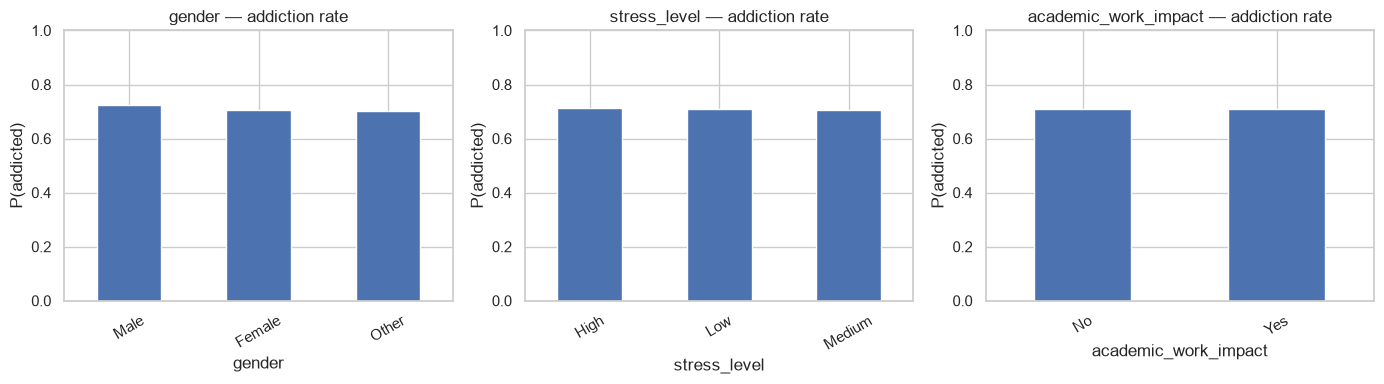

In [17]:
# --- Categorical features vs target ---
cat_cols = ['gender', 'stress_level', 'academic_work_impact']
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cat_cols):
    rates = train.groupby(col)[TARGET].mean().sort_values(ascending=False)
    rates.plot(kind='bar', ax=ax, color='#4C72B0', edgecolor='white')
    ax.set_title(f'{col} — addiction rate')
    ax.set_ylabel('P(addicted)')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

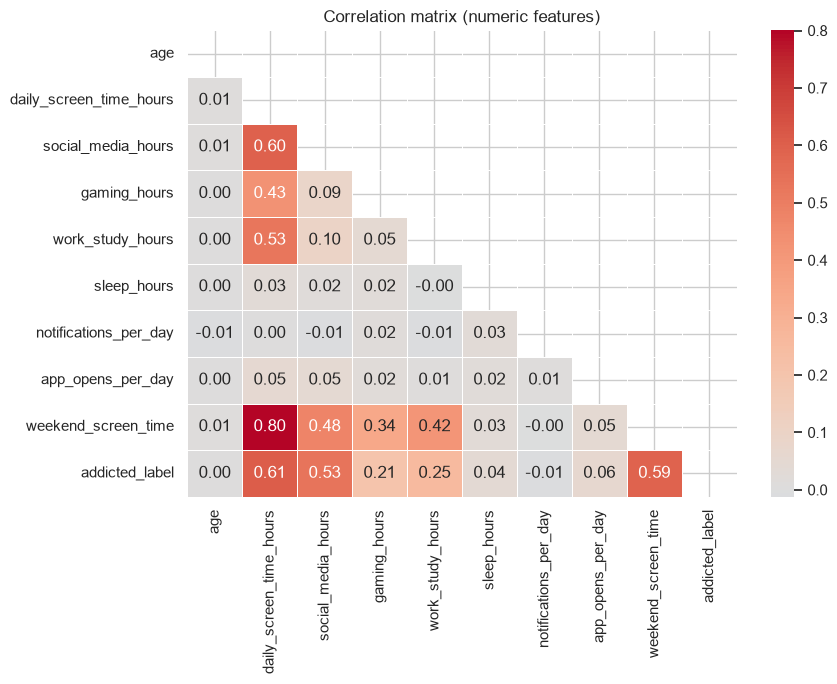

In [18]:
# --- Correlation heatmap ---
corr = train[num_cols + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax)
ax.set_title('Correlation matrix (numeric features)')
plt.tight_layout()
plt.show()

## 4. Preprocessing & Feature Engineering

In [19]:
def preprocess(df, is_train=True):
    df = df.copy()

    # --- Drop id ---
    df = df.drop(columns=['id'], errors='ignore')

    # --- Fill missing: numeric → median, categorical → 'Unknown' ---
    num_cols = ['age', 'daily_screen_time_hours', 'social_media_hours',
                'gaming_hours', 'work_study_hours', 'sleep_hours',
                'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']
    cat_cols = ['gender', 'stress_level', 'academic_work_impact']

    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())
    for col in cat_cols:
        df[col] = df[col].fillna('Unknown')

    # --- Encode categoricals ---
    # stress_level: ordinal (Low < Medium < High)
    stress_map = {'Low': 0, 'Medium': 1, 'High': 2, 'Unknown': -1}
    df['stress_level'] = df['stress_level'].map(stress_map).fillna(-1).astype(int)

    # gender: label encode
    gender_map = {'Male': 0, 'Female': 1, 'Other': 2, 'Unknown': 3}
    df['gender'] = df['gender'].map(gender_map).fillna(3).astype(int)

    # academic_work_impact: binary
    impact_map = {'No': 0, 'Yes': 1, 'Unknown': 2}
    df['academic_work_impact'] = df['academic_work_impact'].map(impact_map).fillna(2).astype(int)

    # --- Feature Engineering ---
    df['screen_to_sleep_ratio']    = df['daily_screen_time_hours'] / (df['sleep_hours'] + 1e-3)
    df['social_plus_gaming']       = df['social_media_hours'] + df['gaming_hours']
    df['total_active_hours']       = df['social_media_hours'] + df['gaming_hours'] + df['work_study_hours']
    df['notif_per_app_open']       = df['notifications_per_day'] / (df['app_opens_per_day'] + 1e-3)
    df['weekend_vs_daily_ratio']   = df['weekend_screen_time'] / (df['daily_screen_time_hours'] + 1e-3)
    df['leisure_hours']            = df['social_media_hours'] + df['gaming_hours']
    df['daily_minus_sleep']        = 24 - df['sleep_hours'] - df['daily_screen_time_hours']
    df['high_stress']              = (df['stress_level'] == 2).astype(int)

    return df


train_proc = preprocess(train, is_train=True)
test_proc  = preprocess(test,  is_train=False)

feature_cols = [c for c in train_proc.columns if c != TARGET]
X = train_proc[feature_cols]
y = train_proc[TARGET]
X_test = test_proc[feature_cols]

print(f'Features: {len(feature_cols)}')
print(feature_cols)

Features: 20
['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time', 'gender', 'stress_level', 'academic_work_impact', 'screen_to_sleep_ratio', 'social_plus_gaming', 'total_active_hours', 'notif_per_app_open', 'weekend_vs_daily_ratio', 'leisure_hours', 'daily_minus_sleep', 'high_stress']


## 5. Baseline — LightGBM (5-Fold Stratified CV)

In [20]:
lgbm_params = {
    'objective':       'binary',
    'metric':          'auc',
    'boosting_type':   'gbdt',
    'n_estimators':    2000,
    'learning_rate':   0.05,
    'num_leaves':      127,
    'max_depth':       -1,
    'min_child_samples': 50,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq':    5,
    'reg_alpha':       0.1,
    'reg_lambda':      1.0,
    'random_state':    SEED,
    'verbose':         -1,
    'n_jobs':          -1,
}

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof_lgbm   = np.zeros(len(X))
test_lgbm  = np.zeros(len(X_test))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(**lgbm_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(100, verbose=False),
            lgb.log_evaluation(500)
        ]
    )

    oof_lgbm[val_idx]  = model.predict_proba(X_val)[:, 1]
    test_lgbm         += model.predict_proba(X_test)[:, 1] / N_FOLDS

    fold_auc = roc_auc_score(y_val, oof_lgbm[val_idx])
    print(f'  Fold {fold+1} AUC: {fold_auc:.5f}')

lgbm_oof_auc = roc_auc_score(y, oof_lgbm)
print(f'\n LightGBM OOF AUC: {lgbm_oof_auc:.5f}')

[500]	valid_0's auc: 0.962099
[1000]	valid_0's auc: 0.962433
  Fold 1 AUC: 0.96247
[500]	valid_0's auc: 0.962746
  Fold 2 AUC: 0.96292
[500]	valid_0's auc: 0.963401
  Fold 3 AUC: 0.96353
[500]	valid_0's auc: 0.963799
  Fold 4 AUC: 0.96399
[500]	valid_0's auc: 0.962583
[1000]	valid_0's auc: 0.962796
  Fold 5 AUC: 0.96281

 LightGBM OOF AUC: 0.96314


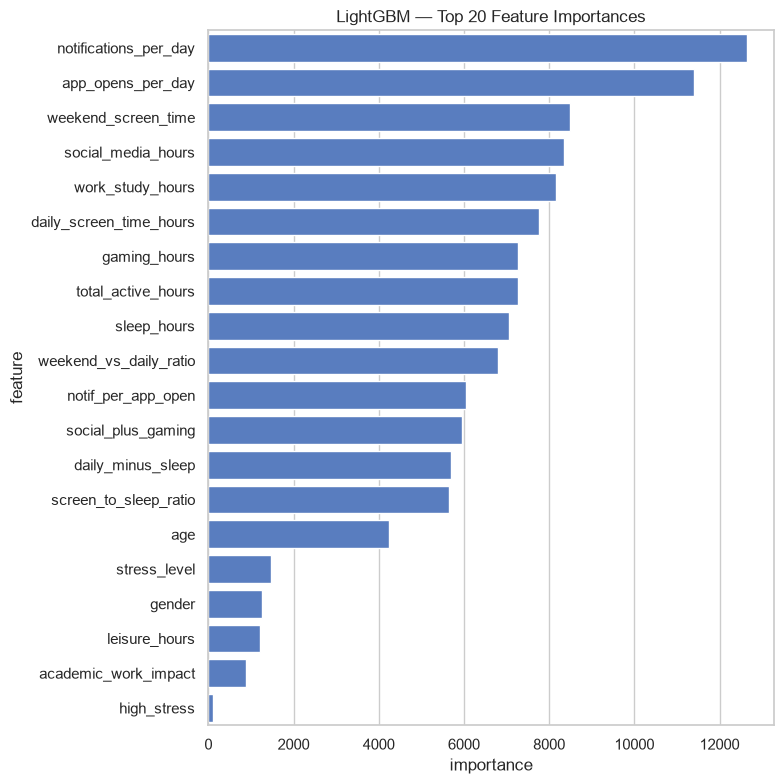

In [21]:
# Feature importance (last fold's model)
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(data=importance_df.head(20), y='feature', x='importance', ax=ax)
ax.set_title('LightGBM — Top 20 Feature Importances')
plt.tight_layout()
plt.show()

## 6. XGBoost — 5-Fold CV

In [26]:
xgb_params = {
    'objective':          'binary:logistic',
    'eval_metric':        'auc',
    'n_estimators':       2000,
    'learning_rate':      0.05,
    'max_depth':          6,
    'min_child_weight':   50,
    'subsample':          0.8,
    'colsample_bytree':   0.8,
    'reg_alpha':          0.1,
    'reg_lambda':         1.0,
    'random_state':       SEED,
    'tree_method':        'hist',
    'device':             'cpu',
    'verbosity':          0,
    'n_jobs':             -1,
}

oof_xgb  = np.zeros(len(X))
test_xgb = np.zeros(len(X_test))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model_xgb = xgb.XGBClassifier(**xgb_params, early_stopping_rounds=100)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    oof_xgb[val_idx]  = model_xgb.predict_proba(X_val)[:, 1]
    test_xgb         += model_xgb.predict_proba(X_test)[:, 1] / N_FOLDS

    fold_auc = roc_auc_score(y_val, oof_xgb[val_idx])
    print(f'  Fold {fold+1} AUC: {fold_auc:.5f}')

xgb_oof_auc = roc_auc_score(y, oof_xgb)
print(f'\n XGBoost OOF AUC: {xgb_oof_auc:.5f}')

  Fold 1 AUC: 0.96323
  Fold 2 AUC: 0.96366
  Fold 3 AUC: 0.96409
  Fold 4 AUC: 0.96488
  Fold 5 AUC: 0.96347

 XGBoost OOF AUC: 0.96386


## 7. CatBoost — 5-Fold CV

In [27]:
cat_params = {
    'iterations':        2000,
    'learning_rate':     0.05,
    'depth':             6,
    'l2_leaf_reg':       3.0,
    'eval_metric':       'AUC',
    'random_seed':       SEED,
    'early_stopping_rounds': 100,
    'verbose':           False,
    'task_type':         'CPU',
}

oof_cat  = np.zeros(len(X))
test_cat = np.zeros(len(X_test))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model_cat = CatBoostClassifier(**cat_params)
    model_cat.fit(
        X_tr, y_tr,
        eval_set=(X_val, y_val),
        use_best_model=True
    )

    oof_cat[val_idx]  = model_cat.predict_proba(X_val)[:, 1]
    test_cat         += model_cat.predict_proba(X_test)[:, 1] / N_FOLDS

    fold_auc = roc_auc_score(y_val, oof_cat[val_idx])
    print(f'  Fold {fold+1} AUC: {fold_auc:.5f}')

cat_oof_auc = roc_auc_score(y, oof_cat)
print(f'\n CatBoost OOF AUC: {cat_oof_auc:.5f}')

  Fold 1 AUC: 0.96029
  Fold 2 AUC: 0.96084
  Fold 3 AUC: 0.96124
  Fold 4 AUC: 0.96207
  Fold 5 AUC: 0.96075

 CatBoost OOF AUC: 0.96104


## 8. Ensemble — Weighted Blend

In [28]:
# Weight each model proportionally to its OOF AUC
aucs = np.array([lgbm_oof_auc, xgb_oof_auc, cat_oof_auc])
weights = aucs / aucs.sum()

print('Model OOF AUC scores:')
for name, auc, w in zip(['LightGBM', 'XGBoost', 'CatBoost'], aucs, weights):
    print(f'  {name:10s}: {auc:.5f}  (weight={w:.3f})')

oof_blend  = weights[0] * oof_lgbm  + weights[1] * oof_xgb  + weights[2] * oof_cat
test_blend = weights[0] * test_lgbm + weights[1] * test_xgb + weights[2] * test_cat

blend_auc = roc_auc_score(y, oof_blend)
print(f'\n Ensemble OOF AUC: {blend_auc:.5f}')

Model OOF AUC scores:
  LightGBM  : 0.96314  (weight=0.333)
  XGBoost   : 0.96386  (weight=0.334)
  CatBoost  : 0.96104  (weight=0.333)

 Ensemble OOF AUC: 0.96349


## 9. Generate Submission

In [29]:
sub['addicted_label'] = test_blend

# Sanity checks
assert sub['addicted_label'].between(0, 1).all(), 'Predictions must be probabilities [0,1]'
assert sub.shape[0] == test.shape[0], 'Row count mismatch with test set'

sub.to_csv('submission.csv', index=False)

print(' submission.csv saved!')
print(f'   Shape: {sub.shape}')
print(f'   Prediction range: [{sub["addicted_label"].min():.4f}, {sub["addicted_label"].max():.4f}]')
sub.head()

 submission.csv saved!
   Shape: (296302, 2)
   Prediction range: [0.0002, 1.0000]


,id,addicted_label
0,691369,0.998869
1,691370,0.933348
2,691371,0.952026
3,691372,0.988423
4,691373,0.997912


## 10. Results Summary

    Model OOF AUC
 LightGBM 0.96314
  XGBoost 0.96386
 CatBoost 0.96104
 Ensemble 0.96349


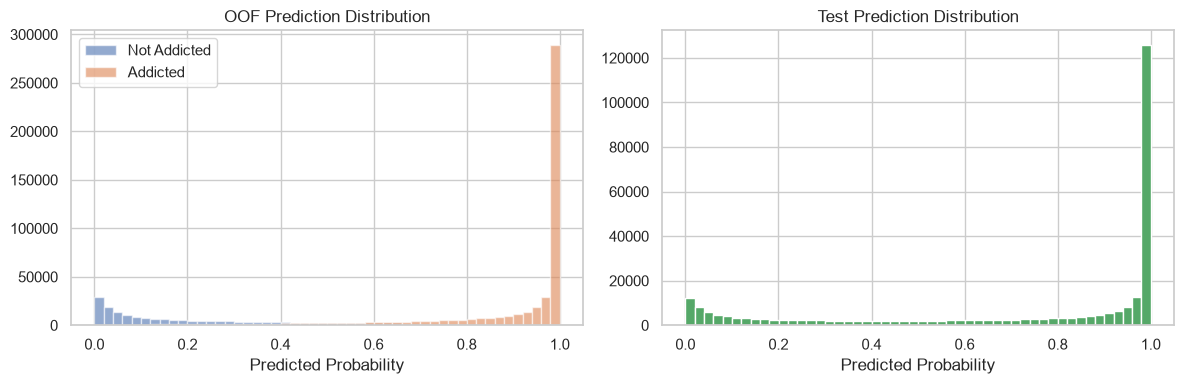

In [31]:
results = pd.DataFrame({
    'Model':   ['LightGBM', 'XGBoost', 'CatBoost', ' Ensemble'],
    'OOF AUC': [lgbm_oof_auc, xgb_oof_auc, cat_oof_auc, blend_auc]
})
results['OOF AUC'] = results['OOF AUC'].map(lambda x: f'{x:.5f}')
print(results.to_string(index=False))

# Plot OOF predictions distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(oof_blend[y == 0], bins=50, alpha=0.6, label='Not Addicted', color='#4C72B0')
axes[0].hist(oof_blend[y == 1], bins=50, alpha=0.6, label='Addicted',     color='#DD8452')
axes[0].set_title('OOF Prediction Distribution')
axes[0].set_xlabel('Predicted Probability')
axes[0].legend()

axes[1].hist(test_blend, bins=50, color='#55A868')
axes[1].set_title('Test Prediction Distribution')
axes[1].set_xlabel('Predicted Probability')

plt.tight_layout()
plt.show()